# Topic Modeling in NLP: Complete Notes + Methods + Google Colab Practicals

**Name :** Ashis Kumar Lenka  
**PRN:** 202401110068
**Batch:** A1
**Dataset:** 20 Newsgroups (real newsgroup posts, 4 categories, built into scikit-learn)

## Learning outcomes
By the end, you should be able to:
1. Explain topic modeling and distinguish it from text classification.
2. Preprocess a real text corpus and create numerical representations.
3. Implement **LDA, NMF, LSA and BERTopic** (BERTopic is optional and needs extra installation).
4. Inspect topic words, document-topic distributions, and visualizations.
5. Check discovered topics against known categories (possible because this dataset has labels).
6. Compare methods, understand limitations, and design a small experiment.

> **Important:** Topic models discover statistical or semantic patterns. They do not automatically know the correct human meaning of a topic. Interpret top words and representative documents, then assign topic labels yourself. In this notebook we *do* have true categories, but only to **evaluate** the models afterwards; the models never see them.

## 1. What is topic modeling?

Topic modeling is an **unsupervised NLP** approach that identifies recurring themes in a collection of documents without requiring pre-assigned topic labels.

**Example uses**
- Group student feedback into teaching, assessment, infrastructure, and placements.
- Explore themes in research-paper abstracts.
- Discover themes in customer reviews or news articles.
- Summarize large collections of documents for exploratory analysis.

### Topic modeling vs. text classification
| Topic modeling | Text classification |
|---|---|
| Usually unsupervised | Usually supervised |
| Topic labels are not given in advance | Training examples have known labels |
| Discovers patterns in a corpus | Predicts predefined categories |
| Example: discover themes in feedback | Example: classify a comment as a complaint |

### Core terminology
- **Corpus:** Collection of documents.
- **Document:** One text item, such as a sentence, review, or article.
- **Token:** A word or text unit.
- **Vocabulary:** Unique terms retained after preprocessing.
- **Document-term matrix (DTM):** Rows are documents; columns are terms; values are counts or weights.
- **Topic:** A group/distribution of words that tend to occur together.
- **Document-topic distribution:** Estimated proportion/probability of each topic in a document.
- **Top words:** Words with high weights/probabilities in a topic.
- **Topic coherence:** A measure intended to reflect how interpretable/co-occurring a topic's words are.
- **Dominant topic:** Topic with the largest estimated document-topic weight. This simplifies a mixture into one label and may hide ambiguity.

## 2. Common topic modeling methods

| Method | Main idea | Strengths | Limitations |
|---|---|---|---|
| **LDA** (Latent Dirichlet Allocation) | Probabilistic model of document-topic and topic-word distributions | Interpretable; classic baseline | Bag-of-words; topic count chosen beforehand; short texts can be difficult |
| **NMF** (Non-negative Matrix Factorization) | Factorizes a non-negative document-term/TF-IDF matrix into document-topic and topic-term factors | Often effective with TF-IDF; relatively straightforward | Topic count chosen beforehand; not a probabilistic generative model |
| **LSA/LSI** (Latent Semantic Analysis/Indexing) | Uses truncated SVD on a term-document matrix | Efficient dimensionality reduction; useful baseline | Components can contain positive and negative weights; interpretation may be less intuitive |
| **pLSA** (Probabilistic Latent Semantic Analysis) | Models word occurrence through latent topics | Historical probabilistic approach | Document parameters can grow with corpus; less common in current basic workflows |
| **BERTopic** | Usually transformer embeddings + dimensionality reduction + clustering + class-based TF-IDF topic representation | Captures semantic similarity; can group paraphrases | More computationally expensive; results depend on embedding/clustering settings |
| **Embedding + clustering** | Create sentence/document embeddings, cluster them, then describe clusters | Flexible and semantically informed | Clusters are not inherently word-probability topics; requires cluster interpretation |
| **Neural topic models** | Learn latent topics using neural encoders/decoders | Flexible representations; research-oriented | More complexity, tuning, and evaluation effort |

**Which should you start with?** Learn LDA first, compare it with NMF, then explore BERTopic for semantic topic discovery. No method is best for every corpus.

## 3. Load the dataset: 20 Newsgroups (4 categories)

We use the **20 Newsgroups** collection, a classic real-world text corpus of newsgroup posts, loaded directly from scikit-learn (no file upload needed; Colab needs internet access for the first download).

We pick four clearly different categories so the topics are easy to interpret:

| Category | Theme |
|---|---|
| `rec.sport.hockey` | Hockey |
| `sci.space` | Space / NASA |
| `sci.med` | Medicine / health |
| `comp.graphics` | Computer graphics |

- Headers, signatures, and quoted replies are removed (`remove=(...)`) so the model learns from the message body, not metadata.
- We sample 300 posts per category (1,200 total) to keep every method fast in Colab.
- The category labels are **kept aside and used only for evaluation**; topic models are unsupervised.
- If the download fails (for example, no internet), the notebook falls back to a tiny built-in demo dataset so you can still run the code.

In [1]:
import numpy as np
import pandas as pd

SEED = 42
CATEGORIES = ["rec.sport.hockey", "sci.space", "sci.med", "comp.graphics"]
PER_CLASS = 300

try:
    from sklearn.datasets import fetch_20newsgroups
    data = fetch_20newsgroups(
        subset="train",
        categories=CATEGORIES,
        remove=("headers", "footers", "quotes"),
        random_state=SEED,
        shuffle=True,
    )
    df = pd.DataFrame({
        "text": data.data,
        "true_label": [data.target_names[t] for t in data.target],
    })
    # keep posts with a reasonable length (drop empty / very short ones)
    df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
    df = df[df["text"].str.split().str.len().between(20, 400)]
    # balanced sample per category
    df = pd.concat(
        [grp.sample(min(len(grp), PER_CLASS), random_state=SEED)
         for _, grp in df.groupby("true_label")]
    )
    df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
    USING_REAL_DATA = True
except Exception as e:
    print("Could not download 20 Newsgroups, using the small demo dataset instead.\nReason:", e)
    demo = {
        "ai_ml": [
            "Machine learning uses algorithms to learn from data.",
            "Deep learning uses neural networks for artificial intelligence.",
            "Python is widely used for machine learning and data science.",
            "Neural networks and deep learning improve image recognition.",
            "Artificial intelligence supports prediction and automation.",
            "Data science uses statistics and machine learning techniques."],
        "infrastructure": [
            "Students need better classrooms and laboratory facilities.",
            "The college needs projectors and modern computer laboratories.",
            "Good infrastructure improves the student learning experience.",
            "Libraries should provide more books, computers, and study spaces."],
        "careers": [
            "Students are looking for internships and placement opportunities.",
            "Companies recruit students with programming and technical skills.",
            "Internships provide practical experience and career development.",
            "Career guidance helps students prepare for technical interviews."],
        "teaching": [
            "The exam schedule should be announced early.",
            "Assessment feedback helps students understand their mistakes.",
            "Teachers should explain difficult concepts with practical examples.",
            "Project-based learning helps students apply programming skills."],
    }
    df = pd.DataFrame([(t, k) for k, v in demo.items() for t in v], columns=["text", "true_label"])
    USING_REAL_DATA = False

documents = df["text"].tolist()
true_labels = df["true_label"].tolist()

print("Using real 20 Newsgroups data:", USING_REAL_DATA)
print("Number of documents:", len(documents))
print("\nDocuments per category:")
print(df["true_label"].value_counts())
print("\nAverage words per document:", round(df["text"].str.split().str.len().mean(), 1))
print("\nExample documents:")
for i in range(3):
    print(f"[{true_labels[i]}] {documents[i][:250]}...\n")

Using real 20 Newsgroups data: True
Number of documents: 1200

Documents per category:
true_label
sci.space           300
sci.med             300
comp.graphics       300
rec.sport.hockey    300
Name: count, dtype: int64

Average words per document: 107.8

Example documents:
[sci.space] Voyager has the unusual luck to be on a stable trajectory out of the solar system. All it's doing is collecting fields data, and routinely squirting it down. One of the mariners is also in stable solar orbit, and still providing similiar solar data. ...

[sci.med] Obesssive Compulsive Disorder (not to be confused with Obsessive Compulsive _Personality_ Disorder !) is an acute anxiety disorder characterized by either obsessions (persistent intrusive thoughts that cause anxiety when not entertained), or compulsi...

[comp.graphics] We are interested in purchasing a grayscale printer that offers a good resoltuion for grayscale medical images. Can anybody give me some recommendations on these products in the

## 4. Preprocessing notes

Typical steps may include:
1. Normalize case.
2. Remove or normalize punctuation, URLs, numbers, and extra whitespace.
3. Tokenize text.
4. Remove stop words where appropriate.
5. Consider lemmatization or stemming if useful.
6. Build features (and drop very rare / very common terms with `min_df` and `max_df`).

**Real text is messy:** newsgroup posts contain e-mail addresses, URLs, numbers, and typos. We strip e-mails/URLs below and keep only alphabetic tokens of length 3 or more.

**Caution:** Do not automatically remove every frequent word or every short word. Terms such as “not” can change sentiment; domain-specific terms may be important. Preserve phrases like “machine learning” when appropriate using n-grams. Preprocessing should fit the task and language.

**Note:** LDA, NMF, and LSA use the cleaned text. **BERTopic** works better on the original (lightly cleaned) sentences, so we pass it `documents`, not `clean_documents`.

In [2]:
import re

def basic_clean(text):
    text = text.lower()
    text = re.sub(r"\S+@\S+", " ", text)          # e-mail addresses
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # URLs
    text = re.sub(r"[^a-z\s]", " ", text)          # keep letters only
    text = re.sub(r"\b\w{1,2}\b", " ", text)       # drop 1-2 letter tokens
    text = re.sub(r"\s+", " ", text).strip()
    return text

clean_documents = [basic_clean(doc) for doc in documents]
print("Before:", documents[0][:300])
print("\nAfter: ", clean_documents[0][:300])

Before: Voyager has the unusual luck to be on a stable trajectory out of the solar system. All it's doing is collecting fields data, and routinely squirting it down. One of the mariners is also in stable solar orbit, and still providing similiar solar data. Something in a planetary orbit, is subject to much

After:  voyager has the unusual luck stable trajectory out the solar system all doing collecting fields data and routinely squirting down one the mariners also stable solar orbit and still providing similiar solar data something planetary orbit subject much more complex forces comsats stable geosynch orbits


## 5. Create count and TF-IDF features

- **CountVectorizer:** represents each document by term counts.
- **TF-IDF:** gives more weight to terms frequent in a document but less common across the corpus.
- LDA is commonly used with count data.
- NMF and LSA often work well with TF-IDF representations.
- `min_df=5` removes terms appearing in fewer than 5 documents (mostly typos/rare words); `max_df=0.5` removes terms appearing in more than half of the documents (too generic to separate topics).

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Real corpus: filter rare/very common terms. Tiny demo corpus: keep everything.
MIN_DF = 5 if USING_REAL_DATA else 1
MAX_DF = 0.5 if USING_REAL_DATA else 1.0

count_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=MIN_DF,
    max_df=MAX_DF,
)
X_count = count_vectorizer.fit_transform(clean_documents)

tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=MIN_DF,
    max_df=MAX_DF,
)
X_tfidf = tfidf_vectorizer.fit_transform(clean_documents)

print("Count matrix shape:", X_count.shape)
print("TF-IDF matrix shape:", X_tfidf.shape)
print("Example vocabulary:", count_vectorizer.get_feature_names_out()[:25])

Count matrix shape: (1200, 2255)
TF-IDF matrix shape: (1200, 2255)
Example vocabulary: ['abc' 'ability' 'able' 'absolutely' 'accept' 'acceptance' 'accepted'
 'access' 'according' 'account' 'accurate' 'acid' 'acids' 'act' 'action'
 'active' 'activities' 'activity' 'actual' 'actually' 'acute' 'adams'
 'add' 'added' 'addition']


## 6. Helper function: display top words

We will reuse this function for LDA, NMF, and LSA. Top words help interpret components but do not prove that a topic is meaningful.

In [4]:
def show_top_words(model, feature_names, n_words=10, method_name="Model"):
    print(f"\n===== {method_name}: top words =====")
    for topic_idx, component in enumerate(model.components_):
        top_indices = component.argsort()[-n_words:][::-1]
        words = [feature_names[i] for i in top_indices]
        print(f"Topic {topic_idx + 1}: " + ", ".join(words))

# Method 1 — LDA (Latent Dirichlet Allocation)

## 7. LDA concept and notes

LDA is a probabilistic generative topic model. At a high level:
- Each document has a mixture of topics.
- Each topic has a distribution over words.
- The model estimates these distributions from word counts.

A document may be, for example, 70% space and 30% medicine in the model's estimated topic mixture (say, a post about the health effects of spaceflight). These values are not ground-truth labels.

**Important parameters**
- `n_components`: number of topics requested.
- `max_iter`: maximum training iterations.
- `random_state`: seed for repeatability.
- `learning_method`: batch or online optimization strategy.

Choose the number of topics by comparing interpretability, coherence, stability, and usefulness for the task—not only by choosing the model with the most topics.

In [5]:
from sklearn.decomposition import LatentDirichletAllocation

n_topics_lda = 4
lda_model = LatentDirichletAllocation(
    n_components=n_topics_lda,
    max_iter=30,
    random_state=SEED,
    learning_method="batch"
)
lda_model.fit(X_count)

lda_terms = count_vectorizer.get_feature_names_out()
show_top_words(lda_model, lda_terms, n_words=10, method_name="LDA")


===== LDA: top words =====
Topic 1: space, nasa, earth, orbit, launch, pens, april, station, new, year
Topic 2: thanks, know, graphics, does, use, software, like, program, need, using
Topic 3: don, people, know, just, like, time, msg, think, food, doctor
Topic 4: game, team, like, think, hockey, just, play, don, good, games


## 8. LDA document-topic probabilities

`transform()` returns one topic-weight vector per document. For each document, the weights sum to approximately 1. The dominant topic is the largest weight, but inspect the full distribution when a document is mixed or ambiguous.

In [6]:
from IPython.display import display

lda_doc_topics = lda_model.transform(X_count)
lda_topic_cols = [f"LDA_Topic_{i+1}" for i in range(n_topics_lda)]

lda_results = pd.DataFrame(lda_doc_topics, columns=lda_topic_cols)
lda_results.insert(0, "Document", [d[:100] + "..." for d in documents])
lda_results.insert(1, "True_Category", true_labels)
lda_results["Dominant_Topic"] = lda_doc_topics.argmax(axis=1) + 1

display(lda_results.head(15).round(3))

,Document,True_Category,LDA_Topic_1,LDA_Topic_2,LDA_Topic_3,LDA_Topic_4,Dominant_Topic
0,Voyager has the unusual luck to be on a stable...,sci.space,0.986,0.005,0.004,0.004,1
1,Obesssive Compulsive Disorder (not to be confu...,sci.med,0.004,0.096,0.895,0.004,3
2,We are interested in purchasing a grayscale pr...,comp.graphics,0.023,0.928,0.026,0.023,2
3,"Ah, so now we're into European player bashing?...",rec.sport.hockey,0.195,0.006,0.006,0.793,4
4,: I've been trying to view .tga files created ...,comp.graphics,0.006,0.981,0.006,0.006,2
5,"Well, pardon me for trying to continue the dis...",sci.space,0.002,0.002,0.002,0.994,4
6,"[stuff deleted] Ok, here's the solution to you...",rec.sport.hockey,0.005,0.005,0.005,0.985,4
7,I think I can. Largely as a result of efforts ...,sci.space,0.406,0.250,0.336,0.008,1
8,My vote goes to John Vanbiesbrouck. His mask h...,rec.sport.hockey,0.010,0.009,0.009,0.972,4
9,"There are many organisms, viral, bacterial, an...",sci.med,0.005,0.005,0.985,0.005,3


## 9. LDA visualization: dominant-topic counts

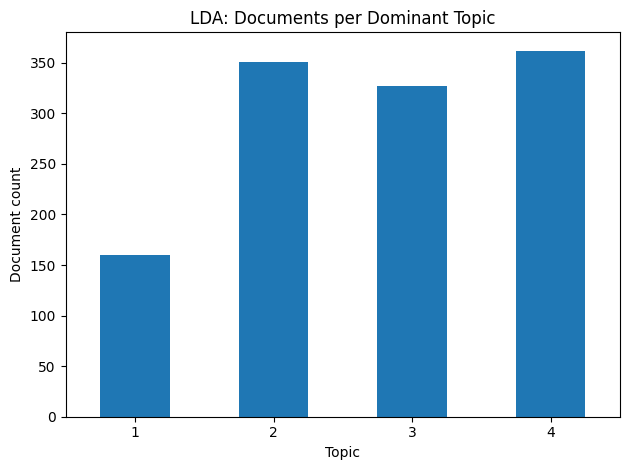

In [7]:
import matplotlib.pyplot as plt

lda_results["Dominant_Topic"].value_counts().sort_index().plot(kind="bar")
plt.title("LDA: Documents per Dominant Topic")
plt.xlabel("Topic")
plt.ylabel("Document count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9b. LDA vs. the true categories (sanity check)

Because 20 Newsgroups has known categories, we can check whether the *unsupervised* topics line up with them. Each row below is a true category; each column is an LDA topic. A good result has one dominant column per row. Topic numbers are arbitrary, so the order of columns will not match the order of categories.

**Adjusted Rand Index (ARI):** 1.0 means perfect agreement with the true grouping; about 0 means random. Do not expect 1.0, since topic models find word patterns, not the exact newsgroup structure.

In [8]:
from sklearn.metrics import adjusted_rand_score

print("LDA — true category (rows) vs. dominant topic (columns):")
display(pd.crosstab(lda_results["True_Category"], lda_results["Dominant_Topic"]))
print("Adjusted Rand Index:", round(adjusted_rand_score(true_labels, lda_results["Dominant_Topic"]), 3))

LDA — true category (rows) vs. dominant topic (columns):


Dominant_Topic,1,2,3,4
True_Category,,,,
comp.graphics,6,267,10,17
rec.sport.hockey,37,7,6,250
sci.med,6,28,257,9
sci.space,111,49,54,86


Adjusted Rand Index: 0.472


# Method 2 — NMF (Non-negative Matrix Factorization)

## 10. NMF concept and notes

NMF factorizes a non-negative feature matrix into two lower-dimensional matrices. Informally:
- one matrix represents how strongly documents relate to topics;
- the other represents how strongly terms relate to topics.

NMF is not the same as LDA and does not produce the same probabilistic interpretation. TF-IDF is a common input for NMF. Select the number of components and compare top words and document assignments.

In [9]:
from sklearn.decomposition import NMF

n_topics_nmf = 4
nmf_model = NMF(
    n_components=n_topics_nmf,
    init="nndsvda",
    random_state=SEED,
    max_iter=500
)
W_nmf = nmf_model.fit_transform(X_tfidf)
H_nmf = nmf_model.components_

tfidf_terms = tfidf_vectorizer.get_feature_names_out()
show_top_words(nmf_model, tfidf_terms, n_words=10, method_name="NMF")


===== NMF: top words =====
Topic 1: space, don, people, just, like, think, msg, time, know, food
Topic 2: gordon banks, banks, shameful, shameful surrender, chastity intellect, chastity, surrender soon, surrender, jxp, intellect
Topic 3: game, team, hockey, play, players, games, season, year, nhl, league
Topic 4: thanks, graphics, files, does, know, program, advance, looking, mail, file


## 11. NMF document-topic weights

NMF outputs non-negative factor weights. They are **not automatically probabilities** and generally do not sum to 1. For a simple comparison, choose the topic with the largest weight.

,Document,True_Category,NMF_Topic_1,NMF_Topic_2,NMF_Topic_3,NMF_Topic_4,Dominant_Topic
0,Voyager has the unusual luck to be on a stable...,sci.space,0.075,0.000,0.000,0.008,1
1,Obesssive Compulsive Disorder (not to be confu...,sci.med,0.034,0.001,0.000,0.010,1
2,We are interested in purchasing a grayscale pr...,comp.graphics,0.008,0.005,0.002,0.059,4
3,"Ah, so now we're into European player bashing?...",rec.sport.hockey,0.010,0.023,0.147,0.000,3
4,: I've been trying to view .tga files created ...,comp.graphics,0.020,0.000,0.000,0.121,4
5,"Well, pardon me for trying to continue the dis...",sci.space,0.113,0.000,0.003,0.000,1
6,"[stuff deleted] Ok, here's the solution to you...",rec.sport.hockey,0.019,0.000,0.117,0.000,3
7,I think I can. Largely as a result of efforts ...,sci.space,0.071,0.000,0.000,0.000,1
8,My vote goes to John Vanbiesbrouck. His mask h...,rec.sport.hockey,0.000,0.000,0.110,0.000,3
9,"There are many organisms, viral, bacterial, an...",sci.med,0.069,0.009,0.000,0.000,1


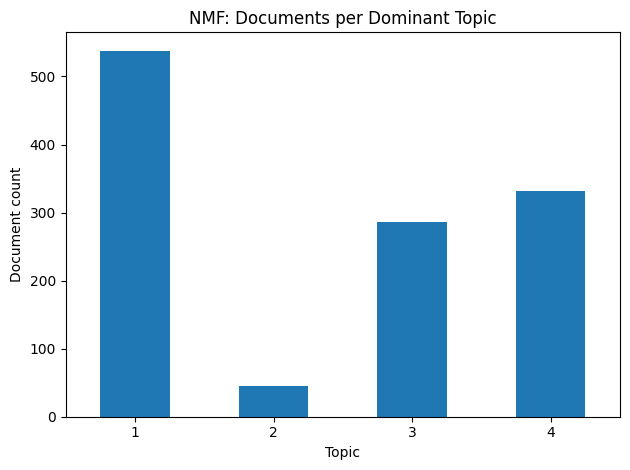

NMF — true category (rows) vs. dominant topic (columns):


Dominant_Topic,1,2,3,4
True_Category,,,,
comp.graphics,41,1,5,253
rec.sport.hockey,16,0,274,10
sci.med,218,43,2,37
sci.space,263,1,5,31


Adjusted Rand Index: 0.469


In [10]:
nmf_dominant = W_nmf.argmax(axis=1) + 1
nmf_results = pd.DataFrame(W_nmf, columns=[f"NMF_Topic_{i+1}" for i in range(n_topics_nmf)])
nmf_results.insert(0, "Document", [d[:100] + "..." for d in documents])
nmf_results.insert(1, "True_Category", true_labels)
nmf_results["Dominant_Topic"] = nmf_dominant
display(nmf_results.head(15).round(3))

nmf_results["Dominant_Topic"].value_counts().sort_index().plot(kind="bar")
plt.title("NMF: Documents per Dominant Topic")
plt.xlabel("Topic")
plt.ylabel("Document count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("NMF — true category (rows) vs. dominant topic (columns):")
display(pd.crosstab(nmf_results["True_Category"], nmf_results["Dominant_Topic"]))
print("Adjusted Rand Index:", round(adjusted_rand_score(true_labels, nmf_results["Dominant_Topic"]), 3))

# Method 3 — LSA / LSI (Latent Semantic Analysis)

## 12. LSA concept and notes

LSA applies truncated Singular Value Decomposition (SVD) to a term-document feature matrix. It finds latent dimensions that summarize patterns of term usage.

- It is often used for dimensionality reduction and semantic search.
- Components can contain positive and negative weights.
- It is not a probabilistic topic model like LDA.
- Component interpretation may be less direct than LDA or NMF.

We use TF-IDF features and inspect the largest positive-weight terms for a simple demonstration.

In [11]:
from sklearn.decomposition import TruncatedSVD

n_topics_lsa = 4
lsa_model = TruncatedSVD(n_components=n_topics_lsa, random_state=SEED)
X_lsa = lsa_model.fit_transform(X_tfidf)

show_top_words(lsa_model, tfidf_terms, n_words=10, method_name="LSA (largest positive weights)")
print("\nExplained variance ratio per component:")
print(lsa_model.explained_variance_ratio_.round(3))

# LSA values can be negative, so use the component with the largest absolute value as a rough assignment
lsa_dominant = np.abs(X_lsa).argmax(axis=1) + 1
print("\nLSA — true category (rows) vs. strongest component (columns):")
display(pd.crosstab(pd.Series(true_labels, name="True_Category"), pd.Series(lsa_dominant, name="Component")))
print("Adjusted Rand Index:", round(adjusted_rand_score(true_labels, lsa_dominant), 3))


===== LSA (largest positive weights): top words =====
Topic 1: don, like, know, just, think, soon, gordon, banks, gordon banks, chastity intellect
Topic 2: intellect, intellect shameful, skepticism, skepticism chastity, chastity, chastity intellect, shameful, shameful surrender, surrender soon, surrender
Topic 3: game, team, hockey, play, players, season, games, nhl, year, league
Topic 4: msg, space, food, people, don, just, think, chinese, disease, moon

Explained variance ratio per component:
[0.005 0.015 0.009 0.007]

LSA — true category (rows) vs. strongest component (columns):


Component,1,2,3,4
True_Category,,,,
comp.graphics,174,0,123,3
rec.sport.hockey,135,0,158,7
sci.med,227,37,3,33
sci.space,265,0,10,25


Adjusted Rand Index: 0.082


# Method 4 — BERTopic (embedding-based topic modeling)

## 13. BERTopic concept and notes

BERTopic commonly combines:
1. Transformer-based document embeddings.
2. Dimensionality reduction (often UMAP).
3. Clustering (often HDBSCAN).
4. Class-based TF-IDF to describe clusters with representative words.

It can capture semantic similarity better than raw word-count methods for some tasks, but it can be slower and requires more dependencies. Some documents may be assigned to an outlier topic, commonly represented by `-1`.

**Unlike LDA/NMF, BERTopic chooses the number of topics itself.** On this 4-category dataset it may return more than 4 topics (sub-themes such as different hockey teams or space missions) plus an outlier group. That is normal, not an error.

**Optional Colab section:** Installation and embedding 1,200 posts can take a few minutes (faster with *Runtime → Change runtime type → GPU*). The install can fail if package versions or runtime resources change. If it fails, continue with LDA/NMF/LSA above.

In [12]:
# Optional: install BERTopic and its dependencies.
# Run this cell only if you want to try BERTopic.
%pip -q install bertopic

In [13]:
# Optional BERTopic training cell. Run after successful installation.
from bertopic import BERTopic
from umap import UMAP

# Fixed random_state makes UMAP (and therefore the topics) repeatable
umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED)

bertopic_model = BERTopic(
    language="english",
    umap_model=umap_model,
    min_topic_size=15,
    verbose=False,
)
# Use the original (lightly cleaned) text, not the stop-word-stripped version
bertopic_topics, bertopic_probs = bertopic_model.fit_transform(documents)

display(bertopic_model.get_topic_info().head(12))

print("\nExample topic terms:")
for topic_id in sorted(set(bertopic_topics)):
    if topic_id != -1:
        print(f"Topic {topic_id}:", [w for w, _ in bertopic_model.get_topic(topic_id)[:8]])

print("\nBERTopic — true category (rows) vs. topic id (columns; -1 = outliers):")
display(pd.crosstab(pd.Series(true_labels, name="True_Category"), pd.Series(bertopic_topics, name="Topic")))

# Optional interactive visualizations (if supported by the runtime):
# bertopic_model.visualize_topics()
# bertopic_model.visualize_barchart(top_n_topics=8)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,Topic,Count,Name,Representation,Representative_Docs
0,0,607,0_the_of_to_and,"[the, of, to, and, is, in, that, it, this, you]","[Be sure to say ""chronic"" dizziness, not just ..."
1,1,304,1_the_to_and_of,"[the, to, and, of, is, for, in, it, on, that]",[I am involve in a Distant Learning project an...
2,2,289,2_the_to_in_and,"[the, to, in, and, of, that, is, he, was, for]","[Well, I gotta tell ya, last night's Leafs gam..."



Example topic terms:
Topic 0: ['the', 'of', 'to', 'and', 'is', 'in', 'that', 'it']
Topic 1: ['the', 'to', 'and', 'of', 'is', 'for', 'in', 'it']
Topic 2: ['the', 'to', 'in', 'and', 'of', 'that', 'is', 'he']

BERTopic — true category (rows) vs. topic id (columns; -1 = outliers):


Topic,0,1,2
True_Category,,,
comp.graphics,17,283,0
rec.sport.hockey,13,0,287
sci.med,288,10,2
sci.space,289,11,0


# Method 5 — Embeddings + clustering (conceptual alternative)

Instead of using word counts, encode each document as a dense semantic vector with a sentence-transformer model, then cluster the vectors (for example, with K-Means). Inspect the documents in each cluster and extract representative words or use a language model to help summarize them.

**Difference from BERTopic:** BERTopic packages a particular embedding + reduction + clustering + topic-description workflow. A custom embedding-clustering pipeline lets you choose each component yourself.

In [14]:
# Optional simple clustering baseline using TF-IDF + K-Means.
# This is clustering, not a probabilistic topic model.
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=SEED, n_init=10)
cluster_labels = kmeans.fit_predict(X_tfidf)

cluster_results = pd.DataFrame({
    "Document": [d[:100] + "..." for d in documents],
    "True_Category": true_labels,
    "Cluster": cluster_labels,
})
display(cluster_results.sort_values("Cluster").head(15))

print("K-Means — true category (rows) vs. cluster (columns):")
display(pd.crosstab(cluster_results["True_Category"], cluster_results["Cluster"]))
print("Adjusted Rand Index:", round(adjusted_rand_score(true_labels, cluster_labels), 3))

,Document,True_Category,Cluster
17,I was there in 1976. I suppose it must have di...,sci.med,0
1159,Probably she meant that your blood pressure we...,sci.med,0
1141,Your medical school library should have books ...,sci.med,0
1126,No one can answer that. If she gets reflex sym...,sci.med,0
1073,I'm sure the Pittsburgh group has published th...,sci.med,0
1034,Dangerous only to immune suppressed persons an...,sci.med,0
1005,"No, the neiseria meningococcus is one of the m...",sci.med,0
948,I agree. Adding layers of managers and bureauc...,sci.med,0
880,Compartment syndrome occurs when swelling happ...,sci.med,0
879,You can probably get this information by calli...,sci.med,0


K-Means — true category (rows) vs. cluster (columns):


Cluster,0,1,2,3
True_Category,,,,
comp.graphics,0,86,2,212
rec.sport.hockey,0,50,244,6
sci.med,41,240,0,19
sci.space,0,289,0,11


Adjusted Rand Index: 0.36


### Optional: true embeddings + K-Means

The cell above uses TF-IDF, so it is still word-count based. For a genuinely semantic version, encode each post with a sentence-transformer model and cluster the embeddings. `all-MiniLM-L6-v2` is small and fast. This needs `sentence-transformers` (installed together with BERTopic). Skip this if BERTopic installation failed.

In [15]:
from sentence_transformers import SentenceTransformer

st_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = st_model.encode(documents, show_progress_bar=True, batch_size=64)

emb_kmeans = KMeans(n_clusters=4, random_state=SEED, n_init=10)
emb_labels = emb_kmeans.fit_predict(embeddings)

print("Embeddings + K-Means — true category (rows) vs. cluster (columns):")
display(pd.crosstab(pd.Series(true_labels, name="True_Category"), pd.Series(emb_labels, name="Cluster")))
print("Adjusted Rand Index:", round(adjusted_rand_score(true_labels, emb_labels), 3))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/19 [00:00<?, ?it/s]

Embeddings + K-Means — true category (rows) vs. cluster (columns):


Cluster,0,1,2,3
True_Category,,,,
comp.graphics,268,2,0,30
rec.sport.hockey,1,2,275,22
sci.med,3,265,0,32
sci.space,7,8,0,285


Adjusted Rand Index: 0.772


# Method 6 — pLSA and neural topic models (theory notes)

## 14. pLSA (Probabilistic Latent Semantic Analysis)
pLSA models word occurrences using latent topics and document-specific topic mixtures. It is historically important and helped lead to LDA. A common limitation is that it does not provide LDA's same prior-based treatment of unseen documents; its document-specific parameters can grow with the training corpus.

## 15. Neural topic models
Neural approaches use neural networks, latent-variable models, variational autoencoders, or embedding-based representations to learn topic structure. They can be useful for research but often need more data, tuning, and careful evaluation. BERTopic is an embedding-and-clustering pipeline; it should not be confused with every neural generative topic model.

# 16. Comparing methods

Use this table as a starting point; real performance depends on corpus, language, preprocessing, and purpose.

| Criterion | LDA | NMF | LSA | BERTopic |
|---|---|---|---|---|
| Typical input | Count matrix | Often TF-IDF | Count or TF-IDF | Text + embeddings |
| Topic count | Set beforehand | Set beforehand | Set components | Can discover clusters; settings affect count |
| Probabilistic document-topic mixture | Yes | No | No | Not in the same sense as LDA |
| Semantic embeddings | No | No | No | Usually yes |
| Runtime | Low/moderate | Low/moderate | Low/moderate | Moderate/high |
| Interpretability | Top words + probabilities | Top words + weights | Component terms | Representative words/docs |
| Good first baseline? | Yes | Yes | Useful baseline | Good modern comparison |

## 17. Evaluating topic quality

There is no single metric that proves a topic model is good.

- **Human interpretability:** Can a reader understand a coherent theme from top words and example documents?
- **Topic coherence:** Do important words tend to co-occur in the corpus? Gensim provides common coherence measures such as `c_v` and `u_mass`.
- **Topic diversity:** Are topics repeating the same words or covering distinct themes?
- **Stability:** Do similar topics appear across different random seeds or samples?
- **Downstream usefulness:** Do topics help with the intended task, such as triaging feedback?

**Perplexity note:** LDA perplexity can help compare models under consistent settings, but lower perplexity does not necessarily mean more interpretable topics.

## 18. Optional LDA perplexity comparison

This experiment compares perplexity for different topic counts. Treat it as one diagnostic, not the only selection criterion. Note that this perplexity is computed on the **training data**, so it tends to keep improving as topics are added; for a fair comparison, hold out a test set or combine it with coherence and human judgement. We know the "true" answer here is about 4 categories, but a real corpus would not tell you that.

,n_topics,perplexity
0,2,1472.008555
1,3,1352.789722
2,4,1355.220827
3,5,1378.800773
4,6,1422.053473
5,8,1466.567874


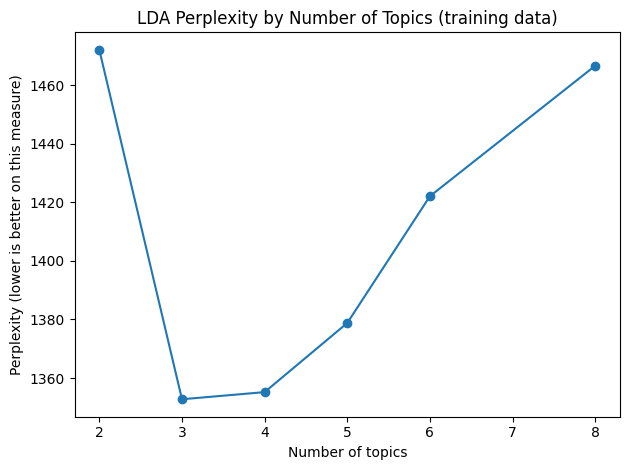

In [16]:
perplexity_rows = []
for k in [2, 3, 4, 5, 6, 8]:
    model = LatentDirichletAllocation(
        n_components=k,
        max_iter=20,
        random_state=SEED,
        learning_method="batch"
    )
    model.fit(X_count)
    perplexity_rows.append({
        "n_topics": k,
        "perplexity": model.perplexity(X_count)
    })

perplexity_df = pd.DataFrame(perplexity_rows)
display(perplexity_df)

plt.plot(perplexity_df["n_topics"], perplexity_df["perplexity"], marker="o")
plt.title("LDA Perplexity by Number of Topics (training data)")
plt.xlabel("Number of topics")
plt.ylabel("Perplexity (lower is better on this measure)")
plt.tight_layout()
plt.show()

## 18b. Optional: topic coherence with Gensim

Coherence (`c_v`) checks whether a topic's top words tend to appear together in the same documents. Higher is generally better. This uses Gensim's LDA, so scores are not identical to scikit-learn's LDA, but the trend across topic counts is informative. If Gensim is unavailable, skip this cell.

,n_topics,c_v_coherence
0,2,0.399
1,3,0.396
2,4,0.394
3,5,0.378
4,6,0.372
5,8,0.338


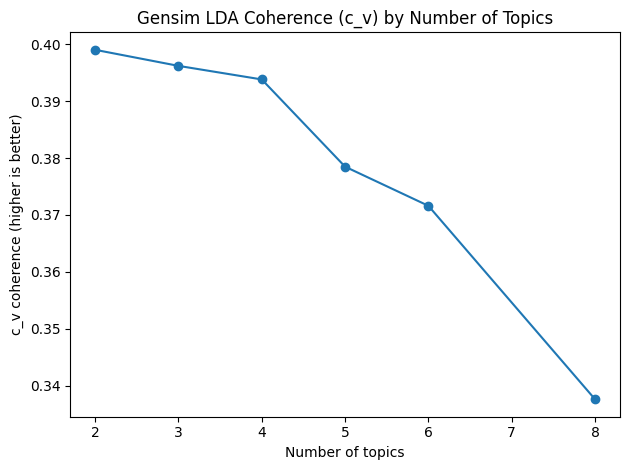

In [17]:
%pip -q install gensim

from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel

tokenized = [[w for w in doc.split() if w not in count_vectorizer.get_stop_words()] for doc in clean_documents]
dictionary = Dictionary(tokenized)
dictionary.filter_extremes(no_below=MIN_DF, no_above=MAX_DF)
corpus = [dictionary.doc2bow(t) for t in tokenized]

coherence_rows = []
for k in [2, 3, 4, 5, 6, 8]:
    g_lda = LdaModel(corpus=corpus, id2word=dictionary, num_topics=k,
                     random_state=SEED, passes=5, iterations=50)
    cm = CoherenceModel(model=g_lda, texts=tokenized, dictionary=dictionary, coherence="c_v")
    coherence_rows.append({"n_topics": k, "c_v_coherence": cm.get_coherence()})

coherence_df = pd.DataFrame(coherence_rows)
display(coherence_df.round(3))

plt.plot(coherence_df["n_topics"], coherence_df["c_v_coherence"], marker="o")
plt.title("Gensim LDA Coherence (c_v) by Number of Topics")
plt.xlabel("Number of topics")
plt.ylabel("c_v coherence (higher is better)")
plt.tight_layout()
plt.show()

# 19. Student lab tasks

1. Run LDA with 3, 4, 5, and 6 topics. Record the top 10 words for each and note when topics start to split or duplicate.
2. Run NMF with the same topic counts and compare themes with LDA.
3. Give each topic a human-readable label (for example, “Hockey games”, “Space missions”) based on top words **and** at least three representative documents.
4. Use the cross-tab and Adjusted Rand Index to compare LDA, NMF, LSA, K-Means, and BERTopic. Which matches the true categories best? Why might the ones that score lower still be useful?
5. Find documents where the dominant LDA topic disagrees with the true category. Read them: is the model wrong, or is the post genuinely mixed (for example, a medical post about space)?
6. Test unigram features (`ngram_range=(1, 1)`) versus unigram + bigram features.
7. Change `min_df` and `max_df` and describe how the vocabulary size and topic quality change.
8. **Harder dataset:** replace `CATEGORIES` with closely related groups (for example `["comp.graphics", "comp.sys.mac.hardware", "comp.sys.ibm.pc.hardware", "comp.windows.x"]`). Do the models still separate them? Why is this harder?
9. **Your own data:** add 50+ comments or abstracts from a domain of your choice (use only data you are allowed to process) and repeat the workflow.
10. Write a short conclusion: which method was most useful for your corpus, and why? Explain why topic IDs such as `Topic 1` are arbitrary and should be interpreted from words and documents.

## 20. Common mistakes and troubleshooting
- **Too few documents:** topic patterns may be unstable or uninformative. (The original 18-sentence demo is only suitable for checking that the code runs.)
- **Too many topics:** themes may fragment into near-duplicates.
- **Too few topics:** distinct themes may be merged.
- **Aggressive preprocessing:** important domain words or negation may be lost.
- **Leaving raw headers/quotes in the text:** the model may pick up e-mail or signature patterns instead of subject matter (we remove them with `remove=(...)`).
- **Misreading NMF weights as probabilities:** NMF weights are not inherently normalized probabilities.
- **Misreading BERTopic `-1`:** often indicates outlier documents, not a meaningful topic label.
- **Treating top words as ground truth:** always read example documents.
- **Treating labels as the only truth:** newsgroup labels are a convenient yardstick, not the “right” topics; a good model may find finer-grained structure.
- **Comparing methods unfairly:** use the same corpus and document boundaries; document differences in preprocessing.
- **Ignoring privacy:** remove identifying or confidential data before uploading text to hosted notebooks.

## 21. Short glossary
- **Unsupervised learning:** Learns patterns without supplied target labels.
- **Tokenization:** Splitting text into tokens.
- **Stop words:** Frequent words often removed for a specific task.
- **N-gram:** Sequence of n tokens; a bigram contains two tokens.
- **TF-IDF:** Term-frequency/inverse-document-frequency weighting.
- **Latent:** Not directly observed; inferred from patterns.
- **Embedding:** Dense vector representation of text.
- **Clustering:** Grouping similar data points.
- **Outlier:** Item not assigned to a regular cluster.
- **Adjusted Rand Index (ARI):** Agreement between two groupings, corrected for chance.
- **Reproducibility:** Ability to repeat an experiment under the same conditions.

## 22. Further reading
- [scikit-learn: 20 Newsgroups dataset](https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset)
- [scikit-learn: Latent Dirichlet Allocation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.LatentDirichletAllocation.html)
- [scikit-learn: Topic extraction with NMF and LDA](https://scikit-learn.org/stable/auto_examples/applications/plot_topics_extraction_with_nmf_lda.html)
- [scikit-learn: Non-negative Matrix Factorization](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.NMF.html)
- [BERTopic documentation](https://maartengr.github.io/BERTopic/)

---
**End of notebook.** Recommended teaching order: concepts → dataset → preprocessing → LDA → NMF → LSA → BERTopic → evaluation and lab tasks.